# F4: herding, capital concentration and market-maker sensitivity

Single-asset experiment, 30 sessions, 5-session warmup, snapshots every 0.02 session.
80 investors and one finite-resource market maker. Pilot seeds 1–3; main seeds 1001–1030.
The protocol was frozen in `docs/guides/f4_simulation.md` before the main runs.
This notebook reads only K3 logs and CSV diagnostics; it does not import the simulation engine.
The sampling horizon is short: results are exploratory and do not establish market realism.

Behavior version: `f4-v2`. Funds use fixed proportional strategy quotas; agents unable to submit an order publish zero.
The f4-v1 results are superseded and kept separately for provenance.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from marketsim.sim.log_schema import load_run

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "runs" / "f4" / "review-v2"
frames = {name: pd.read_csv(RESULTS / name / "summary.csv") for name in ("pilot", "e1", "e2", "e3")}
print("Run counts:", {name: len(frame) for name, frame in frames.items()})
assert {name: len(frame) for name, frame in frames.items()} == {"pilot": 3, "e1": 270, "e2": 90, "e3": 90}

for name, frame in frames.items():
    for run_id in frame.run_id:
        log = load_run(RESULTS / name / run_id)
        assert log.meta["simulation_version"] == "f4-v2"
        assert log.meta["initial_resources"] == log.meta["final_resources"]
        assert log["orders"].filled_qty.sum() == 2 * log["trades"].qty.sum()
        population = log.meta["population"]
        fund_kinds = [population["kinds"][i] for i in population["fund_ids"]]
        assert [fund_kinds.count(kind) for kind in ("valuer", "trend", "noise")] == [4, 2, 2]
print("Validated all 453 f4-v2 logs, resource conservation, execution accounting and fund quotas.")


Run counts: {'pilot': 3, 'e1': 270, 'e2': 90, 'e3': 90}
Validated all 453 f4-v2 logs, resource conservation, execution accounting and fund quotas.


## Diagnostic definitions

`max_drawdown` and `relative_valuation_error` use two-sided midpoint snapshots.
`empty_side_fraction` weights missing-side snapshots by the interval they represent.
`execution_rate` uses eventual fills of orders submitted after warmup.
These are F4 pilot diagnostics; formal validation and shared research metrics belong to D1.
Each independent seed is one statistical unit. The same main seeds allow paired contrasts.


In [2]:
metrics = ["max_drawdown", "empty_side_fraction", "relative_valuation_error", "execution_rate"]
print("Pilot diagnostics:")
print(frames["pilot"][["seed", "wall_time_s", "trade_count"] + metrics].to_string(index=False))
print("\nE1 medians by herding and concentration:")
print(frames["e1"].groupby(["agents.herding.h", "agents.concentration"])[metrics].median().to_string())
print("\nE2 medians by ablation:")
print(frames["e2"].groupby("agents.ablation")[metrics].median().to_string())
print("\nE3 medians by maker spread (ticks):")
print(frames["e3"].groupby("agents.market_maker_spread_ticks")[metrics].median().to_string())


Pilot diagnostics:
 seed  wall_time_s  trade_count  max_drawdown  empty_side_fraction  relative_valuation_error  execution_rate
    1     0.261467          766      0.007726               0.0024                  0.003515        0.158053
    2     0.195152          752      0.003334               0.0000                  0.002632        0.108275
    3     0.184190          773      0.001043               0.0000                  0.005532        0.124641

E1 medians by herding and concentration:
                                       max_drawdown  empty_side_fraction  relative_valuation_error  execution_rate
agents.herding.h agents.concentration                                                                             
0.0              0.2                       0.001820               0.0000                  0.001657        0.128872
                 0.5                       0.003879               0.0040                  0.005503        0.138180
                 0.8                       

In [3]:
def paired_bootstrap(treatment, control, metric, seed):
    pairs = treatment[["seed", metric]].merge(control[["seed", metric]], on="seed", suffixes=("_t", "_c"))
    differences = pairs[f"{metric}_t"].to_numpy() - pairs[f"{metric}_c"].to_numpy()
    rng = np.random.default_rng(seed)
    means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
    low, high = np.quantile(means, [0.025, 0.975])
    return {"mean_difference": differences.mean(), "ci_low": low, "ci_high": high, "paired_runs": len(pairs)}

contrasts = []
e1 = frames["e1"]
for concentration in (0.2, 0.5, 0.8):
    control = e1.query("`agents.herding.h` == 0.0 and `agents.concentration` == @concentration")
    treatment = e1.query("`agents.herding.h` == 0.6 and `agents.concentration` == @concentration")
    for metric in ("max_drawdown", "empty_side_fraction"):
        contrasts.append({"contrast": "h=0.6 minus h=0", "C": concentration, "metric": metric,
                          **paired_bootstrap(treatment, control, metric, 20261029)})
print(pd.DataFrame(contrasts).to_string(index=False))


       contrast   C              metric  mean_difference    ci_low   ci_high  paired_runs
h=0.6 minus h=0 0.2        max_drawdown         0.002813  0.001785  0.003845           30
h=0.6 minus h=0 0.2 empty_side_fraction         0.000000  0.000000  0.000000           30
h=0.6 minus h=0 0.5        max_drawdown         0.003614  0.001216  0.006042           30
h=0.6 minus h=0 0.5 empty_side_fraction        -0.004453 -0.005733 -0.003253           30
h=0.6 minus h=0 0.8        max_drawdown        -0.002452 -0.006508  0.001145           30
h=0.6 minus h=0 0.8 empty_side_fraction        -0.037973 -0.044427 -0.031733           30


In [4]:
print("Representative E1 runs selected by drawdown, never by visual appearance:")
selected = []
for keys, group in e1.groupby(["agents.herding.h", "agents.concentration"]):
    for quantile in (0.5, 0.9):
        target = group.max_drawdown.quantile(quantile)
        row = group.loc[(group.max_drawdown - target).abs().idxmin()]
        log = load_run(RESULTS / "e1" / row.run_id)
        assert log.meta["initial_resources"] == log.meta["final_resources"]
        selected.append({"h": keys[0], "C": keys[1], "quantile": quantile,
                         "seed": int(row.seed), "run_id": row.run_id, "max_drawdown": row.max_drawdown})
print(pd.DataFrame(selected).to_string(index=False))


Representative E1 runs selected by drawdown, never by visual appearance:
  h   C  quantile  seed                  run_id  max_drawdown
0.0 0.2       0.5  1010 f4_65b4dd846dfb0b88c57c      0.001691
0.0 0.2       0.9  1013 f4_7a0ce0557e9abb88fe37      0.004798
0.0 0.5       0.5  1004 f4_1b88c8531e713158d76f      0.003900
0.0 0.5       0.9  1013 f4_550d6596ba5d7fc5e16a      0.011224
0.0 0.8       0.5  1018 f4_37b6411af3687f66ff0c      0.010002
0.0 0.8       0.9  1023 f4_48d79242cc3c1020ba93      0.022104
0.3 0.2       0.5  1006 f4_cc4cca2543f7134ec704      0.002196
0.3 0.2       0.9  1007 f4_fcaeaf5d336f8a51abc9      0.005119
0.3 0.5       0.5  1004 f4_c1c2fa8f3630c64aea7b      0.005900
0.3 0.5       0.9  1016 f4_fd1817188b3cd3fce2c2      0.011538
0.3 0.8       0.5  1006 f4_3db9adf693b6598b1745      0.012020
0.3 0.8       0.9  1008 f4_55de4e9acde84aa79d6b      0.020526
0.6 0.2       0.5  1012 f4_d43ebb54b328e0c941ff      0.004749
0.6 0.2       0.9  1006 f4_955847fa4a83642d6a50      0.0098

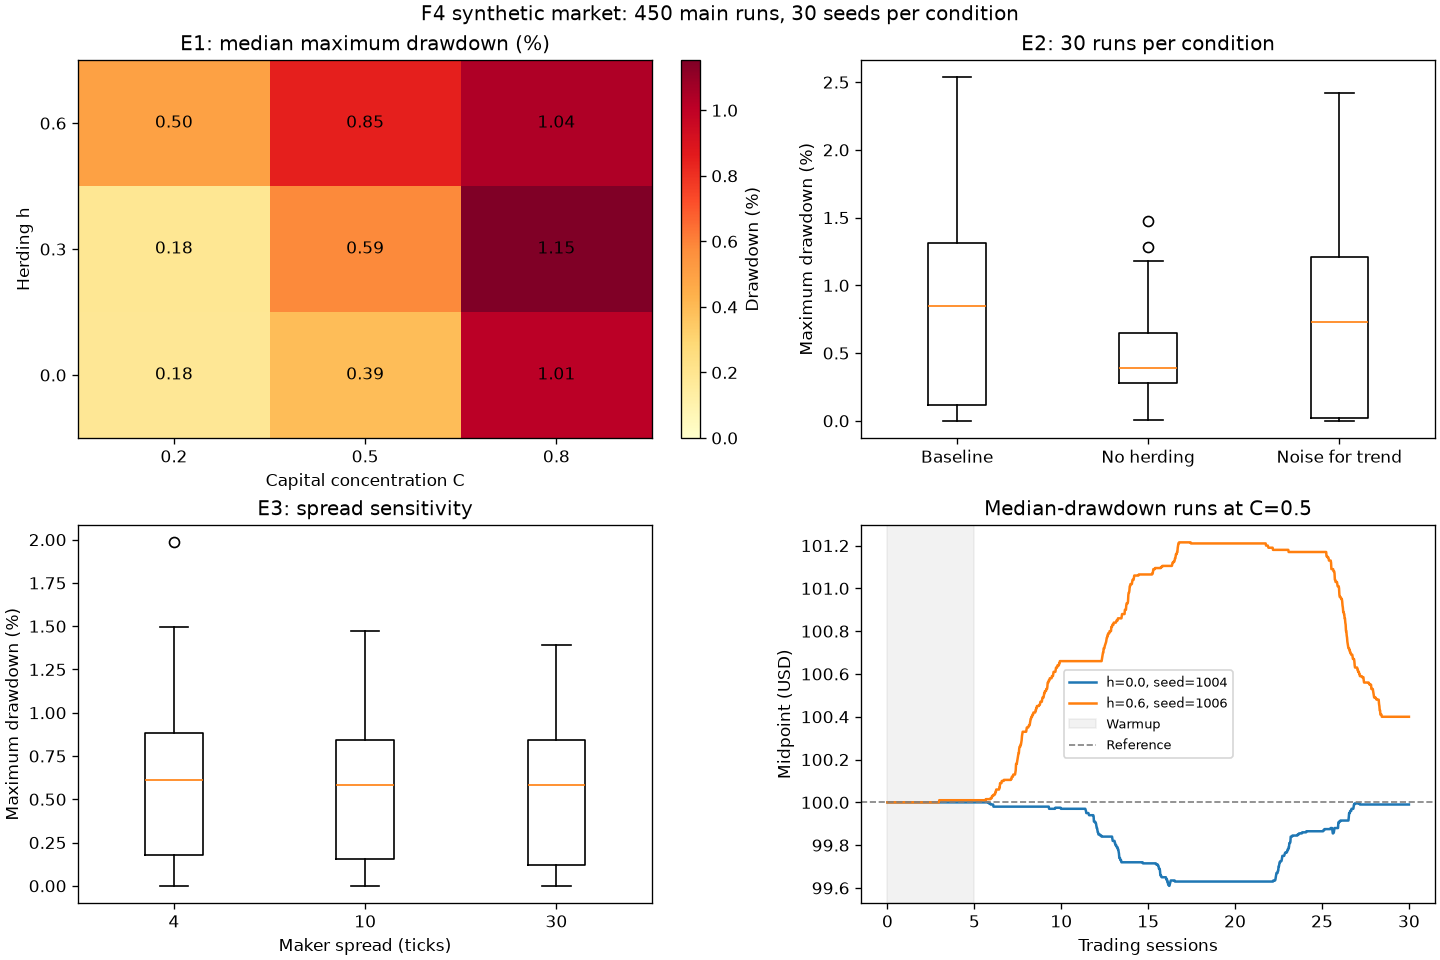

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
heat = e1.pivot_table(index="agents.herding.h", columns="agents.concentration", values="max_drawdown", aggfunc="median")
image = axes[0, 0].imshow(100 * heat.to_numpy(), origin="lower", aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(1, float(100 * heat.to_numpy().max())))
axes[0, 0].set(xticks=range(3), xticklabels=heat.columns, yticks=range(3), yticklabels=heat.index,
               xlabel="Capital concentration C", ylabel="Herding h", title="E1: median maximum drawdown (%)")
for i in range(3):
    for j in range(3):
        axes[0, 0].text(j, i, f"{100 * heat.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=axes[0, 0], label="Drawdown (%)")

labels = ["none", "no_herding", "no_trend"]
axes[0, 1].boxplot([100 * frames["e2"].loc[frames["e2"]["agents.ablation"] == k, "max_drawdown"] for k in labels],
                   tick_labels=["Baseline", "No herding", "Noise for trend"])
axes[0, 1].set(ylabel="Maximum drawdown (%)", title="E2: 30 runs per condition")
axes[0, 1].tick_params(axis="x", labelrotation=0)

spreads = [4, 10, 30]
axes[1, 0].boxplot([100 * frames["e3"].loc[frames["e3"]["agents.market_maker_spread_ticks"] == k, "max_drawdown"]
                   for k in spreads], tick_labels=spreads)
axes[1, 0].set(xlabel="Maker spread (ticks)", ylabel="Maximum drawdown (%)", title="E3: spread sensitivity")

for h in (0.0, 0.6):
    group = e1.query("`agents.herding.h` == @h and `agents.concentration` == 0.5")
    row = group.loc[(group.max_drawdown - group.max_drawdown.median()).abs().idxmin()]
    log = load_run(RESULTS / "e1" / row.run_id)
    book = log["book"]
    valid = (book.best_bid > 0) & (book.best_ask > 0)
    axes[1, 1].plot(book.loc[valid, "t"], (book.loc[valid, "best_bid"] + book.loc[valid, "best_ask"]) / 200,
                    label=f"h={h}, seed={int(row.seed)}")
axes[1, 1].axvspan(0, 5, alpha=0.1, color="gray", label="Warmup")
axes[1, 1].axhline(100, color="gray", linestyle="--", linewidth=1, label="Reference")
axes[1, 1].set(xlabel="Trading sessions", ylabel="Midpoint (USD)", title="Median-drawdown runs at C=0.5")
axes[1, 1].legend(fontsize=8)
fig.suptitle("F4 synthetic market: 450 main runs, 30 seeds per condition")
fig.savefig(RESULTS / "f4_overview.png", dpi=150)
fig.savefig(RESULTS / "f4_overview.svg")
plt.show()


## First findings: f4-v2

At C=0.5, median maximum drawdown is 0.39% at h=0, 0.59% at h=0.3 and 0.85% at h=0.6.
The paired mean difference for h=0.6 minus h=0 is 0.36 percentage points
(95% bootstrap interval: 0.12–0.60). At C=0.8 that interval spans zero, so the herding contrast
is inconclusive there. Median drawdown increases with concentration within each tested h,
but those medians alone do not establish statistical significance for the concentration effect.

Replacing trend signals with noise at h=0.6 gives 0.73% median drawdown; turning herding off
gives 0.39%. Maker spreads of 4/10/30 ticks give median drawdowns of 0.61%/0.59%/0.59%.
The earlier f4-v1 claim of 11.29% median drawdown at h=0.6, C=0.5 is superseded by these reruns.
The two review fixes were applied together, so this comparison does not isolate their individual effects.


## Interpretation limits

The asset dependency graph and historical stock paths are not used in F4.
Funds are a fixed investor subgroup with a different allocation of the same aggregate resources.
In the no-trend ablation, trend agents keep their IDs, resources and wake rates but use noise signals.
The order-status enum lacks manual cancellation and GTD expiry: terminal lifecycle states must be read
from the events table together with orders. See the F4 guide before consuming order status.
A confidence interval spanning zero is reported as an inconclusive contrast. Results apply only to this
parameter range and horizon; longer runs and D1's metrics are needed for broader conclusions.
